In [22]:
!pip install torchviz

In [23]:
import torch
from torchviz import make_dot

# simple derivative

In [ ]:
x=torch.tensor(2.0)
print("x = ",x)
print("Require_grad:",x.requires_grad)

x =  tensor(2.)
Require_grad: False


**requires_grad=True**

In [ ]:
x = torch.tensor(2.0, requires_grad=True)

print("x =", x)
print("Requires gradient:", x.requires_grad)

x = tensor(2., requires_grad=True)
Requires gradient: True


In [ ]:
y = x**2 + 3*x + 2
print("Output y =", y)
print("Requires gradient:", y.requires_grad)

Output y = tensor(12., grad_fn=<AddBackward0>)
Requires gradient: True


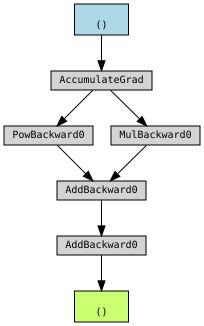

In [ ]:
make_dot(y)

In [ ]:
y.backward()

In [ ]:
print("Gradient of x:", x.grad)

Gradient of x: tensor(7.)


# partial dertivatives

f(x,y)=3x^2+2y

In [ ]:
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(4.0, requires_grad=True)
print(f"x = {x} ,y = {y}")

x = 2.0 ,y = 4.0


In [ ]:
z = 3*x**2 + 2*y

In [ ]:
z

tensor(20., grad_fn=<AddBackward0>)

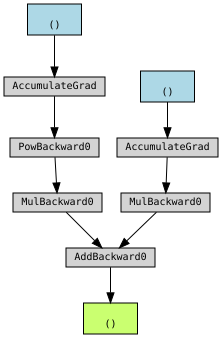

In [ ]:
make_dot(z)

In [ ]:
z.backward()

print("z =", z.item())
print("dz/dx =", x.grad.item())
print("dz/dy =", y.grad.item())

z = 20.0
dz/dx = 12.0
dz/dy = 2.0


# chain rule

y=u^2

u=x+2

In [ ]:
x = torch.tensor(3.0, requires_grad=True)

u = x + 2
y = u**2

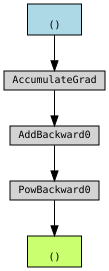

In [ ]:
make_dot(y)

In [ ]:
y.backward()


print("u =", u.item())
print("y =", y.item())
print("dy/dx =", x.grad.item())

u = 5.0
y = 25.0
dy/dx = 10.0


# Gradient accumulation

In [9]:
x = torch.tensor(2.0, requires_grad=True)


In [11]:
y = x**2
y.backward()
print("Second gradient:", x.grad.item())

Second gradient: 8.0


# clearing gradient

In [16]:
x.grad.zero_()
print("Gradient after zeroing:", x.grad.item())

y = x**2
y.backward()

print("Gradient after backward:", x.grad.item())

Gradient after zeroing: 0.0
Gradient after backward: 4.0


# torch.no_grad()

In [20]:
x = torch.tensor(2.0, requires_grad=True)

with torch.no_grad():
    y = x**2


print("x requires grad:", x.requires_grad)
print("y requires grad:", y.requires_grad)

x requires grad: True
y requires grad: False


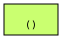

In [24]:
make_dot(y)

# vector

In [ ]:
x = torch.tensor([2.0, 3.0], requires_grad=True)

y = x**2

print("y =", y)

y = tensor([4., 9.], grad_fn=<PowBackward0>)


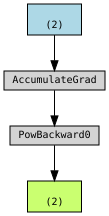

In [ ]:
make_dot(y)

In [ ]:
y.backward(torch.ones_like(y))

print(x.grad)

tensor([4., 6.])


# Neural Network

In [ ]:
x = torch.tensor(13)  # Input
y = torch.tensor(1.0)  # output label

w = torch.tensor(1.0)  # Weight
b = torch.tensor(0.0)  # Bias

In [ ]:
def BCE(prediction, target):
    return -(target * torch.log(prediction)) - ((1 - target) * torch.log(1 - prediction))

In [ ]:
# Forward pass
z = w * x + b
# model prediction
y_pred = torch.sigmoid(z)

# Compute loss
loss = BCE(y_pred, y)
print(f"Loss: {loss}")

Loss: 2.2649790025752736e-06


In [ ]:
dL_dy_pred = (y_pred - y)/(y_pred*(1-y_pred))
dy_pred_dz = y_pred * (1 - y_pred)

dz_dw = x
dz_db = 1

dL_dw = dL_dy_pred * dy_pred_dz * dz_dw
dL_db = dL_dy_pred * dy_pred_dz * dz_db

print(f"Gradient of Loss w.r.t weight: {dL_dw}")
print(f"Gradient of Loss w.r.t bias: {dL_db}")

Gradient of Loss w.r.t weight: -2.944469451904297e-05
Gradient of Loss w.r.t bias: -2.2649765014648438e-06


# Neural Networks Using Autograd

In [ ]:
x = torch.tensor(13)  # Input
y = torch.tensor(1.0)  # output label

w = torch.tensor(1.0,requires_grad=True)  # Weight
b = torch.tensor(0.0,requires_grad=True)  # Bias

In [ ]:
def BCE(prediction, target):
    return -(target * torch.log(prediction)) - ((1 - target) * torch.log(1 - prediction))

In [ ]:
# Forward pass
z = w * x + b
# model prediction
y_pred = torch.sigmoid(z)

# Compute loss
loss = BCE(y_pred, y)
print(f"Loss: {loss}")

Loss: 2.2649790025752736e-06


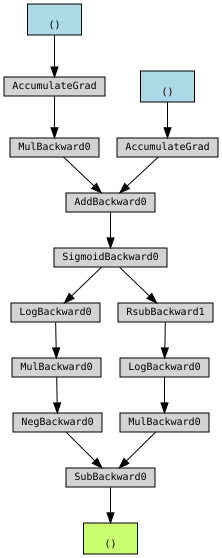

In [ ]:
make_dot(loss)

In [ ]:
loss.backward()

In [ ]:
print(f"Gradient of Loss w.r.t weight: {w.grad}")
print(f"Gradient of Loss w.r.t bias: {b.grad}")

Gradient of Loss w.r.t weight: -2.944469451904297e-05
Gradient of Loss w.r.t bias: -2.2649765014648438e-06


In [ ]:
Gradient of Loss w.r.t weight: -2.944469451904297e-05
Gradient of Loss w.r.t bias: -2.2649765014648438e-06



---



---
Z.I. Turjo

